# **DS - Les 6 - Customer Churn**
## **Les: End-to-End Customer Churn Prediction & Model Evaluation**
  
**Doelstelling**
- Data Wrangling: Werken met relationele data, joins/merges en inconsistenties in sleutels (case sensitivity).
- Feature Engineering & Preprocessing: Opzetten van een lekvrije scikit-learn pipeline met ColumnTransformer.
- Class Imbalance & Modelvergelijking: Trainen en vergelijken van Tree Ensembles (Random Forest, AdaBoost, XGBoost) en Support Vector Machines (SVM).
- Metrieken voor Churn: Begrijpen waarom Accuracy misleidend is, en hoe ROC-AUC, Precision-Recall, en F1-score gekoppeld worden aan businesswaarde (retentiekosten vs. misgelopen inkomsten).
- Productie-gereedheid: Modeltraining encapsuleren in een herbruikbare, parametriseerbare functie en inferentie uitvoeren op nieuwe klanten.

## **Stap 1:** Libraries

In [1]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

import pandas as pd
import numpy as np
import seaborn as sns
import os

In [2]:
os.getcwd()

'c:\\Users\\chayb\\Desktop\\2026-2027 Semester 1\\Machine learning & Forecasting\\Les 6'

## **Stap 2:** Data

In [3]:
df_abonnement = pd.read_csv("abonnement_info.csv")
print(df_abonnement.info())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   CustomerID        7043 non-null   str  
 1   gender            7043 non-null   str  
 2   SeniorCitizen     7043 non-null   int64
 3   Partner           7043 non-null   str  
 4   Dependents        7043 non-null   str  
 5   tenure            7043 non-null   int64
 6   PhoneService      7043 non-null   str  
 7   MultipleLines     7043 non-null   str  
 8   InternetService   7043 non-null   str  
 9   OnlineSecurity    7043 non-null   str  
 10  OnlineBackup      7043 non-null   str  
 11  DeviceProtection  7043 non-null   str  
 12  TechSupport       7043 non-null   str  
 13  StreamingTV       7043 non-null   str  
 14  StreamingMovies   7043 non-null   str  
 15  Contract          7043 non-null   str  
 16  PaperlessBilling  7043 non-null   str  
dtypes: int64(2), str(15)
memory usage: 935.5 KB


In [4]:
df_payment_features = pd.read_csv("betalingen_features.csv")
df_payment_features.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CustomerID      7043 non-null   str    
 1   PaymentMethod   7043 non-null   str    
 2   MonthlyCharges  7043 non-null   float64
 3   TotalCharges    7043 non-null   str    
 4   card_number     7043 non-null   str    
dtypes: float64(1), str(4)
memory usage: 275.2 KB


In [5]:
df_churn_lables = pd.read_csv("klanten_churn.csv")
df_churn_lables.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   card_number  7043 non-null   str  
 1   Churn        7043 non-null   str  
dtypes: str(2)
memory usage: 110.2 KB


In [6]:
# Stap 1: Normaliseer CustomerID 
# In abonnement_info staat bv. "BE-25795E", in betalingen_features "BE-25795e" -> hoofdletters/spaties gelijk trekken
df_abonnement["CustomerID_clean"] = df_abonnement["CustomerID"].str.strip().str.lower()
df_payment_features["CustomerID_clean"] = df_payment_features["CustomerID"].str.strip().str.lower()

# Stap 2: Koppel abonnement en payment features via CustomerID_clean
df_merged = df_abonnement.merge(
    df_payment_features.drop(columns=["CustomerID"]),
    on="CustomerID_clean",
    how="inner",
)

# Stap 3: Koppel churn labels via card_number
df_complete = df_merged.merge(df_churn_lables, on="card_number", how="inner")

df_complete.head(10)


,CustomerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,CustomerID_clean,PaymentMethod,MonthlyCharges,TotalCharges,card_number,Churn
0,BE-25795E,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,be-25795e,Electronic check,29.85,29.85,****127276,No
1,BE-86820B,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,be-86820b,Mailed check,56.95,1889.5,****582526,No
2,BE-92386C,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,be-92386c,Mailed check,53.85,108.15,****181894,Yes
3,BE-97498E,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,be-97498e,Bank transfer (automatic),42.30,1840.75,****553311,No
4,BE-54131C,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,be-54131c,Electronic check,70.70,151.65,****314231,Yes
5,BE-77221E,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,be-77221e,Electronic check,99.65,820.5,****634973,Yes
6,BE-10769D,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,Yes,No,Month-to-month,Yes,be-10769d,Credit card (automatic),89.10,1949.4,****811065,No
7,BE-74925F,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,Month-to-month,No,be-74925f,Mailed check,29.75,301.9,****871783,No
8,BE-77969D,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,be-77969d,Electronic check,104.80,3046.05,****562802,Yes
9,BE-93104D,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,One year,No,be-93104d,Bank transfer (automatic),56.15,3487.95,****669621,No


In [7]:
# Stap 4: Opschonen van features identificatoren op die niet bijdragen aan modellering
# ID's en kaartnummers zijn unieke sleutels zonder voorspellende waarde (en kunnen overfitting veroorzaken)
df_complete = df_complete.drop(columns=["CustomerID", "CustomerID_clean", "card_number"])

print(df_complete.describe())
print(df_complete.info())


       SeniorCitizen       tenure  MonthlyCharges
count    7145.000000  7145.000000     7145.000000
mean        0.161931    32.332680       64.735717
std         0.368414    24.534536       30.071956
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.550000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000
<class 'pandas.DataFrame'>
RangeIndex: 7145 entries, 0 to 7144
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7145 non-null   str    
 1   SeniorCitizen     7145 non-null   int64  
 2   Partner           7145 non-null   str    
 3   Dependents        7145 non-null   str    
 4   tenure            7145 non-null   int64  
 5   PhoneService      7145 non-null   str    
 6   MultipleLines     7145 non-null   str    
 7   InternetService   7145 non

In [8]:
# Stap 5: Type casting en missing value inspectie
# "TotalCharges" bevat vaak verborgen spaties (' ') bij nieuwe klanten (tenure = 0)
df_complete["TotalCharges"] = pd.to_numeric(df_complete["TotalCharges"].astype(str).str.strip(), errors="coerce")
print(f"Ontbrekende waarden in TotalCharges: {df_complete['TotalCharges'].isna().sum()}")
# Deze NaN's laten we bewust staan: de SimpleImputer in de pipeline vult ze lekvrij in (enkel gefit op train)

# Encodeer Churn naar numeriek (1 = Ja, 0 = Nee)
churn_target = "Churn"
df_complete[churn_target] = df_complete[churn_target].map({"Yes": 1, "No": 0})

print(f"Gereconstrueerde dataset vorm: {df_complete.shape}")
print(f"Churn verdeling:\n{df_complete[churn_target].value_counts(normalize=True)}")

Ontbrekende waarden in TotalCharges: 11
Gereconstrueerde dataset vorm: (7145, 20)
Churn verdeling:
Churn
0    0.73366
1    0.26634
Name: proportion, dtype: float64


## **Stap 3:** Preprocessing en Train Test Split
  
- Om data leakage te vermijden, definiëren we numerieke en categorische transformaties via ColumnTransformer. 
- De numerieke features worden geschaald (essentieel voor SVM) en categorische variabelen worden one-hot encoded.

In [ ]:
# Features (X) en target (y)
X = df_complete.drop(columns=[churn_target])
y = df_complete[churn_target]

# Train-test split (stratified wegens class imbalance!!)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

print(f"Omvang trainingset: {X_train.shape[0]} | Omvang testset: {X_test.shape[0]}")

Omvang trainingset: 5716 | Omvang testset: 1429


In [10]:
# Identificeer kolomtypen
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

# Preprocessing sub-pipelines
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols),
    ]
)

C:\Users\chayb\AppData\Local\Temp\ipykernel_8172\2993578612.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


## **Stap 4:** ML Pipeline

In [11]:
# Modellen definiëren
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=150, max_depth=8, random_state=42, class_weight="balanced"
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=100, learning_rate=0.5, random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=3,
        random_state=42,
        eval_metric="logloss",
    ),
    "SVM (RBF)": SVC(
        probability=True,  # nodig voor predict_proba (ROC-AUC)
        kernel="rbf",
        C=1.0,
        class_weight="balanced",
        random_state=42,
    ),
}

## **Stap 5:** Training en evaluatie

In [12]:
# Training en evaluatie
results = {}
trained_pipelines = {}

for name, clf in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", clf)])
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "y_proba": y_proba,
    }
    trained_pipelines[name] = pipe

# Vergelijkingstabel
df_metrics = pd.DataFrame(results).T.drop(columns=["y_proba"])
print(df_metrics.round(3))

               Accuracy Precision    Recall  F1-Score   ROC-AUC
Random Forest  0.769769  0.546595  0.800525  0.649627  0.850741
AdaBoost        0.79916  0.658784  0.511811  0.576071  0.848366
XGBoost        0.751575  0.521812  0.816273  0.636643  0.849255
SVM (RBF)      0.749475  0.519263  0.813648  0.633947  0.837367


### **ROC & AUC in de Context van Churn**
#### *1. Waarom geen "Accuracy?"*
De dataset is onevenwichtig: ±73% van de klanten blijft, slechts ±27% churnt. Een "dom" model dat **altijd "geen churn"** voorspelt haalt dus al ±73% accuracy, maar detecteert **geen enkele** churner en heeft dus nul businesswaarde. Accuracy beloont het correct voorspellen van de grote (oninteressante) klasse. Dat zie je ook in de tabel: AdaBoost heeft de hoogste accuracy (±0.80), maar mist ongeveer de helft van de churners (recall ±0.5). Random Forest heeft een lagere accuracy maar vindt ±80% van de churners. Voor churn kijken we daarom naar **Recall, Precision, F1 en ROC-AUC**.

#### *2. Wat toont de ROC-Curve?*
De ROC-curve (Receiver Operating Characteristic) zet voor **alle mogelijke drempelwaarden** (van 1 naar 0) de:
- **True Positive Rate (TPR = Recall)** = TP / (TP + FN) → welk aandeel van de echte churners vangen we?
- **False Positive Rate (FPR)** = FP / (FP + TN) → welk aandeel van de loyale klanten krijgt onterecht een "churn"-label (vals alarm)?

tegen elkaar uit. Elk punt op de curve is één drempel. Hoe meer de curve naar de **linkerbovenhoek** trekt, hoe beter het model churners van loyale klanten scheidt. De diagonaal is een willekeurig model (gokken).

#### *3. De Bedrijfsmatige Vertaling van de Drempelwaarde (Threshold)*
Het model geeft een **kans** op churn; de standaarddrempel 0.50 is willekeurig en zelden optimaal. De keuze van de drempel is een **businessbeslissing** die afhangt van de kosten:
- **False Negative** (churner gemist) → de klant vertrekt: we verliezen alle toekomstige inkomsten (Customer Lifetime Value). Dit is meestal **duur**.
- **False Positive** (loyale klant als churner gemarkeerd) → we geven onnodig een retentiekorting of bellen iemand op: dit kost **relatief weinig**.

Omdat een gemiste churner veel duurder is dan een onnodige promo, kiest men vaak een **lagere drempel** (bv. 0.35): we schuiven op de ROC-curve naar rechtsboven → hogere recall, ten koste van meer valse alarmen. Is het retentiebudget of de callcentercapaciteit beperkt, dan schuift men de drempel omhoog (hogere precision).

#### *4. Area Under the Curve (AUC)*
De AUC is de oppervlakte onder de ROC-curve en vat de prestaties over **alle drempels** samen in één getal, **onafhankelijk van de gekozen drempel en van de class imbalance**:
- **AUC = 0.5** → niet beter dan gokken; **AUC = 1.0** → perfecte scheiding.
- Interpretatie: de AUC is de **kans dat een willekeurige churner een hogere churn-score krijgt dan een willekeurige loyale klant**. Het meet dus hoe goed het model klanten kan **rangschikken** naar risico.

Hier scoren alle modellen rond 0.84–0.85; Random Forest heeft de hoogste AUC (±0.85) en wordt verder als beste model gebruikt. Let wel: een hoge AUC zegt niets over de beste drempel; die kies je nadien op basis van de businesskosten (punt 3).

### **Visualisatie van de ROC-Curven**

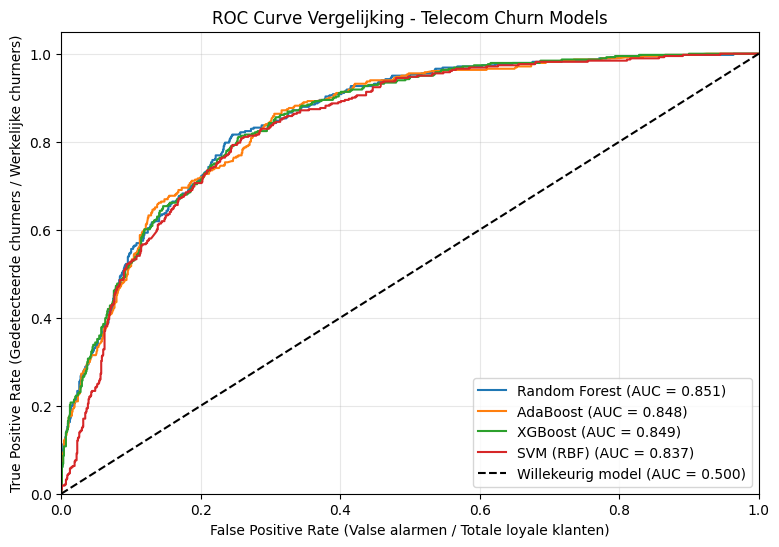

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res["y_proba"])
    roc_score = res["ROC-AUC"]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_score:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Willekeurig model (AUC = 0.500)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (Valse alarmen / Totale loyale klanten)")
plt.ylabel("True Positive Rate (Gedetecteerde churners / Werkelijke churners)")
plt.title("ROC Curve Vergelijking - Telecom Churn Models")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

## **Stap 6:** Predictie

Predictie voor een Nieuwe Klant
We simuleren een nieuwe klant die binnenstroomt via een CRM-formulier en sturen deze door onze best presterende pipeline.

In [14]:
best_model_name = df_metrics["ROC-AUC"].astype(float).idxmax()
best_pipeline = trained_pipelines[best_model_name]
print(f"Beste model op basis van ROC-AUC: {best_model_name}")

# Gegevens van een nieuwe, binnenkomende klant
nieuwe_klant = pd.DataFrame(
    [
        {
            "gender": "Female",
            "SeniorCitizen": 0,
            "Partner": "No",
            "Dependents": "No",
            "tenure": 2,  # Slechts 2 maanden klant (hoog risico)
            "PhoneService": "Yes",
            "MultipleLines": "No",
            "InternetService": "Fiber optic",
            "OnlineSecurity": "No",
            "OnlineBackup": "No",
            "DeviceProtection": "No",
            "TechSupport": "No",
            "StreamingTV": "Yes",
            "StreamingMovies": "Yes",
            "Contract": "Month-to-month",  # Maandcontract (hoog risico)
            "PaperlessBilling": "Yes",
            "PaymentMethod": "Electronic check",
            "MonthlyCharges": 89.50,
            "TotalCharges": 179.0,
        }
    ]
)

# Voorspelling uitvoeren
churn_kans = best_pipeline.predict_proba(nieuwe_klant)[0, 1]
standaard_voorspelling = best_pipeline.predict(nieuwe_klant)[0]

print("\n--- Resultaat Nieuwe Klant ---")
print(f"Geschatte churn-waarschijnlijkheid: {churn_kans:.1%}")
print(f"Standaard classificatie (drempel 0.50): {'CHURN' if standaard_voorspelling == 1 else 'GEEN CHURN'}")

# Zakelijke interventie drempel op 0.35
business_threshold = 0.35
interventie = churn_kans >= business_threshold
print(f"Actie vereist (interventie-drempel {business_threshold:.2f}): {'JA, bied direct retentiepromo aan' if interventie else 'NEE'}")

Beste model op basis van ROC-AUC: Random Forest

--- Resultaat Nieuwe Klant ---
Geschatte churn-waarschijnlijkheid: 89.1%
Standaard classificatie (drempel 0.50): CHURN
Actie vereist (interventie-drempel 0.35): JA, bied direct retentiepromo aan


## **Vragen**

1. Data Leakage & Preprocessing: Waarom moeten StandardScaler en SimpleImputer worden opgenomen in de Pipeline in plaats van vooraf uitgevoerd te worden over de gehele samengevoegde dataset?

2. Business Trade-off bij Churn: Stel dat de telecomoperator beschikt over een callcenterteam dat maandelijks maximaal 200 risicoklanten kan opbellen om hen te overtuigen te blijven. Moet je dan optimaliseren op een hoge Recall of op een hoge Precision@Top-200? Waarom?

3. Hyperparameter Tuning: Wat is het effect van de parameter scale_pos_weight in XGBoost en class_weight='balanced' in Random Forest/SVM op de ROC-curve en de optimale beslissingsdrempel?

4. Data Integriteit: Welke risico's brengt het met zich mee als bij het samenvoegen van relationele databases de primary en foreign keys niet eerst gestandaardiseerd worden (zoals de hoofdletters in CustomerID)? Wat gebeurt er bij een inner join versus een left join?

## **Antwoorden**

**1. Data Leakage & Preprocessing**

Als je de `StandardScaler` en `SimpleImputer` vooraf op de **volledige** dataset fit, worden het gemiddelde, de standaardafwijking en de mediaan ook berekend met de **testdata**. Informatie uit de testset "lekt" dan in de training, waardoor de testscores te optimistisch zijn en niet meer weerspiegelen hoe het model presteert op écht nieuwe klanten. In een `Pipeline` worden de transformaties **enkel op de trainingsdata gefit** (`fit_transform` op train, `transform` op test). Dit geldt ook bij cross-validation: per fold wordt opnieuw enkel op de trainfold gefit. Bovendien bewaart de pipeline de geleerde parameters, zodat een nieuwe klant in productie exact dezelfde preprocessing krijgt (zoals bij de predictie in Stap 6, waar we ruwe data rechtstreeks aan `best_pipeline` geven).

**2. Business Trade-off bij Churn (capaciteit van 200 telefoontjes)**

Optimaliseer op **Precision@Top-200**. De capaciteit is de beperkende factor: je kan hoe dan ook maar 200 klanten bellen. Een hoge recall (zoveel mogelijk churners markeren) levert dan een lijst van bv. 800 klanten op waarvan je er toch maar 200 kan bellen. Wat telt is dat **zoveel mogelijk van die 200 telefoontjes naar echte churners gaan**, zodat geen enkel gesprek verspild wordt aan een klant die toch niet zou vertrekken. Je rangschikt de klanten dus op `predict_proba` en belt de 200 hoogste scores; de drempel wordt impliciet bepaald door de capaciteit en niet door 0.50. Daarom is ook een goede **rangschikking** (hoge AUC / goede precision in de top) belangrijker dan de classificatie op een vaste drempel. (Idealiter rangschik je zelfs op verwachte waarde = churnkans × klantwaarde.)

**3. Hyperparameter Tuning: `scale_pos_weight` en `class_weight='balanced'`**

Beide parameters geven de minderheidsklasse (churners) **meer gewicht** in de loss-functie (`scale_pos_weight` ≈ #negatief / #positief ≈ 2.75 hier, afgerond 3 in ons XGBoost-model; `class_weight='balanced'` weegt elke klasse met n_samples / (n_classes × n_klasse)). Een fout op een churner kost het model dus meer.
- **Effect op de voorspelde kansen / drempel:** het model geeft systematisch **hogere churnkansen**. Op de vaste drempel 0.50 worden er dus meer klanten als churner geclassificeerd → **recall stijgt, precision daalt** (zie RF, XGBoost en SVM met recall ±0.80 tegenover AdaBoost zonder weging met recall ±0.5). De kansen zijn wel niet meer gekalibreerd (een "0.6" betekent niet meer 60% kans). De **optimale beslissingsdrempel schuift omhoog**: zonder weging zou je een drempel < 0.5 moeten kiezen om dezelfde recall te halen; met weging ligt het equivalente punt al rond 0.5.
- **Effect op de ROC-curve:** de ROC-curve is opgebouwd uit **alle** drempels en hangt enkel af van de **rangschikking** van de klanten. Een herweging verschuift vooral de scores, waardoor de ROC-curve en de AUC grotendeels **gelijk blijven** (hooguit een kleine wijziging omdat de bomen/support vectors iets anders geleerd worden). Je beweegt vooral op dezelfde curve naar een ander werkpunt (rechtsboven: hogere TPR, hogere FPR).

**4. Data Integriteit: niet-gestandaardiseerde sleutels**

In `abonnement_info` staat bv. `BE-25795E` en in `betalingen_features` `BE-25795e`. Een join is hoofdlettergevoelig, dus deze sleutels matchen **niet**. Risico's:
- **Inner join:** enkel rijen met een exacte match blijven over. Klanten met een afwijkende schrijfwijze verdwijnen **stil** uit de dataset (hier zelfs allemaal: een inner join op de ruwe `CustomerID` levert **0 rijen** op) → veel minder data en mogelijk een **vertekende steekproef** (bias) als het probleem niet willekeurig verdeeld is (bv. enkel uit één bronsysteem).
- **Left join:** alle klanten uit de linkertabel blijven bewaard, maar de kolommen uit de rechtertabel (`PaymentMethod`, `MonthlyCharges`, `card_number`, ...) worden **NaN** (hier voor alle 7043 klanten). Daarna faalt ook de join met de churn-labels via `card_number`, zodat het target ontbreekt. Als je die NaN's dan "oplost" met een imputer, train je op verzonnen data.
- Daarnaast: **duplicaten in de sleutels** zorgen voor een many-to-many join die rijen vermenigvuldigt. Dat zie je hier ook: 7043 klanten worden na de joins **7145** rijen, omdat er 51 dubbele CustomerID's in beide bestanden zitten. Zulke duplicaten kunnen bovendien in zowel train als test terechtkomen (lichte leakage). Controleer daarom altijd het aantal rijen voor en na een join (of gebruik `validate="one_to_one"` in `pd.merge`) en maak de sleutels eerst schoon (`.str.strip().str.lower()`).

# Oefening **Master Pipeline Functie**
In productieomgevingen wil je hyperparameters, modellen en selectie-strategieën flexibel aanroepen zonder herhalende code.

In [ ]:
def run_churn_pipeline(df, target_col="Churn", model_type="xgboost", test_size=0.20, random_state=42, model_params=None,
    ):
    """
    Traint en evalueert een complete churn-pipeline op maat.
    """
    if model_params is None:
        model_params = {}

    # 1. Feature / target scheiding en split
    X = df.drop(columns=[target_col])
    y = df[target_col]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, stratify=y, random_state=random_state)

    # 2. Preprocessing definitie
    num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
    cat_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                    ]
                ),
                num_cols,
            ),
            (
                "cat",
                Pipeline(
                    steps=[
                        ("imputer", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore")),
                    ]
                ),
                cat_cols,
            ),
        ]
    )

    # 3. Model selectie (initialiseer enkel het gekozen model)
    model_type = model_type.lower()
    if model_type == "random_forest":
        clf = RandomForestClassifier(random_state=random_state, **model_params)
    elif model_type == "adaboost":
        clf = AdaBoostClassifier(random_state=random_state, **model_params)
    elif model_type == "xgboost":
        clf = XGBClassifier(random_state=random_state, eval_metric="logloss", **model_params)
    elif model_type == "svm":
        clf = SVC(probability=True, random_state=random_state, **model_params)
    else:
        raise ValueError(
            f"Onbekend model_type '{model_type}'. Kies uit: random_forest, adaboost, xgboost, svm."
        )

    # 4. Pipeline assembleren en trainen
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", clf)])
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    }

    print(f"{'Model':<10}: {model_type.upper()}")
    for metric, value in metrics.items():
        print(f"{metric:<10}: {value:.4f}")

    return pipeline, metrics


# Voorbeeld: Custom XGBoost aanroep
custom_pipeline, custom_metrics = run_churn_pipeline(
    df=df_complete,
    target_col="Churn",
    model_type="xgboost",
    model_params={
        "n_estimators": 150,
        "max_depth": 3,
        "learning_rate": 0.08,
        "scale_pos_weight": 2.5,
    },
)

C:\Users\chayb\AppData\Local\Temp\ipykernel_8172\2364422991.py:24: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Model     : XGBOOST
Accuracy  : 0.7586
Precision : 0.5318
Recall    : 0.7900
F1-Score  : 0.6357
ROC-AUC   : 0.8494
